# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      str    
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), str(1)
memory usage: 260.0 bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     4000 non-null   int64
 1   first_name  4000 non-null   str  
 2   last_name   4000 non-null   str  
 3   age         4000 non-null   int64
 4   city        3531 non-null   str  
 5   reg_date    4000 non-null   str  
 6   plan        4000 non-null   str  
 7   churn_date  466 non-null    str  
dtypes: int64(2), str(6)
memory usage: 250.1 KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  str    
 3   date      39950 non-null  str    
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), str(2)
memory usage: 1.8 MB


**Lo que dice la estructura:**
- `plans` tiene 2 filas (Basico y Premium) y está completo.
- `users` tiene 4,000 clientes y 8 columnas. `city` y `churn_date` tienen nulos, y las fechas (`reg_date`, `churn_date`) vienen como **texto**, no como fecha.
- `usage` tiene 40,000 eventos (llamadas y mensajes). `date` también viene como **texto**, y `duration` y `length` tienen muchos nulos. Todo esto se revisa en el paso 2.

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?

**Diagnóstico:**

*users*
- `city`: 469 nulos (**11.7%**). Está en el rango de 5–30%: no se puede adivinar la ciudad de un cliente, así que **se deja como nulo**. (Más adelante aparecen otros 96 `"?"` que también son nulos disfrazados.)
- `churn_date`: 3,534 nulos (**88.4%**). Por la regla general se eliminaría, pero aquí el nulo **no es un dato perdido: significa que el cliente no ha cancelado**. **Se conserva**, porque distingue a los clientes activos de los que se fueron.
- El resto de las columnas está completo.

*usage*
- `date`: 50 nulos (**0.1%**). Es menos del 5% y la fecha no se necesita para sumar el uso por cliente: **se deja como nulo** y esos eventos se conservan.
- `duration`: 22,076 nulos (**55.2%**) y `length`: 17,896 nulos (**44.7%**). No parece un problema de captura: una llamada no tiene longitud y un mensaje no tiene duración. **Se dejan como nulos** (lo comprobamos en el paso 3.2).

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
display(users.describe())
print('Registros con age = -999:', (users['age'] == -999).sum())

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


Registros con age = -999: 55


- La columna `user_id` es un **identificador**: su media o desviación no significan nada. Solo confirma 4,000 IDs, del 10000 al 13999.
- La columna `age` tiene un **mínimo de -999**, una edad imposible: es un **sentinel** (55 registros, 1.4%). Por su culpa la media (33.7) queda muy por debajo de la mediana (47) y la desviación estándar es enorme (123). Sin ese valor, las edades van de 18 a 79 años.

In [13]:
# explorar columnas numéricas de usage
display(usage.describe())

# ¿Los máximos son casos aislados o un valor que se repite? ¿En qué tipo de evento aparecen?
print('Registros con duration mayor a 60 minutos:')
print(usage.loc[usage['duration'] > 60, ['type', 'duration']].value_counts())
print()
print('Registros con length mayor a 200 caracteres:')
print(usage.loc[usage['length'] > 200, ['type', 'length']].value_counts())

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


Registros con duration mayor a 60 minutos:
type  duration
text  120.0       16
call  120.0       14
Name: count, dtype: int64

Registros con length mayor a 200 caracteres:
type  length
text  1490.0    18
call  1490.0    12
Name: count, dtype: int64


- Las columnas `id` y `user_id` son **identificadores**: `id` numera cada evento (1 a 40,000) y `user_id` dice a qué cliente pertenece; sus estadísticas no tienen significado.
- La columna `duration` tiene mediana de 3.5 minutos, pero un **máximo de 120**. Ese valor se repite **exactamente 30 veces** y ningún otro registro pasa de 60 minutos: no es comportamiento real, es un **sentinel**. Además, 16 de esos 30 registros son **mensajes**, que no deberían tener duración.
- La columna `length` tiene mediana de 50 caracteres, pero un **máximo de 1,490**, que también se repite **exactamente 30 veces** (ningún otro pasa de 200). Un SMS no llega ni a 200 caracteres: es otro **sentinel**, y 12 de esos registros son **llamadas**, que no deberían tener longitud.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(users[col].value_counts(dropna=False))
    print()

city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: count, dtype: int64

plan
Basico     2595
Premium    1405
Name: count, dtype: int64



- La columna `city` tiene 6 ciudades válidas: 3 de México (CDMX 730, GDL 450, MTY 407) y 3 de Colombia (Bogotá 808, Medellín 616, Cali 424). Además tiene **96 registros con `"?"`** (sentinel de ciudad desconocida) y 469 nulos.
- La columna `plan` está limpia: solo `Basico` (2,595) y `Premium` (1,405), sin errores de escritura.

In [15]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

type
text    22092
call    17908
Name: count, dtype: int64

- La columna `type` está limpia: solo `text` (22,092) y `call` (17,908), sin nulos ni categorías extrañas.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**
- ¿En qué columnas encontraste valores inválidos o sentinels?
- ¿Qué acción tomarías?

**Diagnóstico:**
- `age` = **-999** en 55 registros (1.4%): edad imposible. **Acción:** reemplazar por la mediana de las edades válidas (paso 3.1).
- `city` = **"?"** en 96 registros (2.4%): es un nulo disfrazado. **Acción:** convertirlo a nulo (`pd.NA`). Con los 469 nulos originales, quedan 565 clientes sin ciudad (14.1%).
- `duration` = **120** en 30 registros y `length` = **1,490** en 30 registros: valores repetidos e imposibles, que además aparecen en el tipo de evento equivocado. **Acción (extra):** convertirlos a nulos para que no inflen los minutos de 30 clientes.
- `plan` y `type` no tienen valores inválidos.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

reg_date
2022    1314
2023    1316
2024    1330
2026      40
Name: count, dtype: int64

In [19]:
# Extra: ¿los registros de 2026 son clientes del futuro o un error de captura?
registros_2026 = users[users['reg_date'].dt.year > 2024]
print(registros_2026['reg_date'].value_counts())
print('Usuarios de 2026 que ya tenían uso en 2024:', registros_2026['user_id'].isin(usage['user_id']).sum(), 'de', len(registros_2026))

# Extra: revisión cruzada, ¿alguien usó el servicio antes de registrarse?
primer_uso = usage.groupby('user_id')['date'].min().reset_index(name='primer_uso')
cruce = users.merge(primer_uso, on='user_id')
print('Usuarios con primer uso ANTES de su fecha de registro:', (cruce['primer_uso'] < cruce['reg_date']).sum(), 'de', len(cruce))

reg_date
2026-05-10    40
Name: count, dtype: int64
Usuarios de 2026 que ya tenían uso en 2024: 40 de 40
Usuarios con primer uso ANTES de su fecha de registro: 1302 de 3999


En `reg_date`, los años 2022, 2023 y 2024 tienen ~1,300 registros cada uno, pero hay **40 registros (1%) en 2026**, un año que aún no transcurría cuando se guardaron los datos (llegan hasta 2024). Los 40 tienen **la misma fecha** (10-may-2026) y **los 40 ya usaban el servicio en 2024**: es un error de captura, no clientes del futuro.

Además, la revisión cruzada muestra que **1,302 de 3,999 usuarios (32.6%, incluidos esos 40) aparecen usando el servicio antes de su fecha de registro**, algo imposible: `reg_date` no es confiable para medir la antigüedad de los clientes.

In [20]:
# Revisar los años presentes en `date` de usage
print('Rango de fechas:', usage['date'].min(), 'a', usage['date'].max())
usage['date'].dt.year.value_counts(dropna=False).sort_index()

Rango de fechas: 2024-01-01 00:00:00 a 2024-06-30 00:00:00


date
2024.0    39950
NaN          50
Name: count, dtype: int64

En `date`, los 39,950 eventos con fecha son de **2024**, de enero a junio, dentro del periodo esperado. Los 50 sin año (`NaN`) son los nulos que ya venían en el archivo, no fechas mal escritas.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**Diagnóstico:**
- **Sí hay años imposibles:** 40 registros de `reg_date` en 2026 (1%). **Acción:** marcarlos como nulos (`pd.NaT`, el nulo de las columnas de fecha). No borramos a esos clientes porque el resto de su información (edad, plan, uso) es válida.
- En `date` no hay años fuera de rango: todo es 2024. Los 50 eventos sin fecha (0.1%) se conservan, porque solo necesitamos contarlos por cliente.
- **Extra:** como 1 de cada 3 usuarios aparece usando el servicio antes de registrarse, **no usaremos `reg_date` para sacar conclusiones** y recomendamos revisar cómo se captura.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
# (la mediana se calcula SIN los -999, para que el sentinel no la jale hacia abajo)
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

city
Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: count, dtype: int64

In [23]:
# Marcar fechas futuras como NA para reg_date
# En columnas de fecha, el nulo es pd.NaT ("Not a Time"): con pd.NA, la versión de pandas de la plataforma marca ValueError
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

reg_date
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: count, dtype: int64

#### Extra: sentinels en `usage`
En el paso 2.2 encontramos dos valores imposibles que se repiten exactamente 30 veces cada uno: `duration = 120` y `length = 1490`. Los convertimos a nulos (`np.nan`, porque son columnas numéricas) para que no inflen los minutos de llamada de 30 clientes.

In [24]:
# Reemplazar los sentinels de usage por nulos
usage.loc[usage['duration'] == 120, 'duration'] = np.nan
usage.loc[usage['length'] == 1490, 'length'] = np.nan

# Verificar cambios: ahora los máximos son valores realistas
usage[['duration', 'length']].describe()

,duration,length
count,17894.000000,22074.000000
mean,5.009774,50.173235
std,4.976793,19.884646
min,0.000000,0.000000
25%,1.430000,37.000000
50%,3.490000,50.000000
75%,6.950000,64.000000
max,46.980000,125.000000


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [25]:
# Verificación MAR en usage (Missing At Random) para duration
# proporción de nulos de duration dentro de cada tipo de evento
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000782
text    1.000000
Name: duration, dtype: float64

In [26]:
# Verificación MAR en usage (Missing At Random) para length
# proporción de nulos de length dentro de cada tipo de evento
usage['length'].isna().groupby(usage['type']).mean()

type
call    1.000000
text    0.000815
Name: length, dtype: float64

**Diagnóstico de nulos en `duration` y `length`:** los nulos **dependen por completo de `type`**: el 100% de los mensajes no tiene `duration` y el 100% de las llamadas no tiene `length`. Es un faltante **MAR** (depende de otra variable observada) y además tiene lógica de negocio: una llamada no tiene longitud y un mensaje no tiene duración. **Se dejan como nulos**: imputarlos inventaría información que no existe.

El 0.08% restante (14 llamadas sin duración y 18 mensajes sin longitud) son los sentinels que convertimos a nulos en el paso anterior.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [27]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({'is_text': 'sum', 'is_call': 'sum', 'duration': 'sum'}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text': 'cant_mensajes',
                                      'is_call': 'cant_llamadas',
                                      'duration': 'cant_minutos_llamada'})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Un usuario no tiene ningún registro en usage: el merge le deja NaN en sus 3 columnas de uso.
# Sin registros = 0 mensajes, 0 llamadas y 0 minutos (con NaN, la segmentación del paso 6 lo marcaría como 'Alto uso').
columnas_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print('Usuarios sin registros de uso:', user_profile['cant_llamadas'].isna().sum())
user_profile[columnas_uso] = user_profile[columnas_uso].fillna(0)

user_profile.head(5)

Usuarios sin registros de uso: 1


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [30]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,22.411225
std,17.689919,2.359738,2.145139,15.053351
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.080000
50%,48.000000,5.000000,4.000000,19.670000
75%,63.000000,7.000000,6.000000,30.992500
max,79.000000,17.000000,15.000000,105.540000


In [31]:
# Distribución porcentual del tipo de plan
(user_profile['plan'].value_counts(normalize=True) * 100).round(1)

plan
Basico     64.9
Premium    35.1
Name: proportion, dtype: float64

**Lectura del resumen:**
- Un cliente típico, en los 6 meses de datos (enero a junio de 2024), envía **5 mensajes** y hace **4 llamadas** que suman **~20 minutos** (medianas).
- En mensajes y llamadas, media y mediana son casi iguales (5.5 vs 5; 4.5 vs 4): distribuciones casi simétricas. En minutos, la media (22.4) supera a la mediana (19.7): hay una cola de clientes que hablan bastante más.
- `age` va de 18 a 79 años, con media y mediana de 48.
- El **64.9%** de los clientes tiene plan Básico y el **35.1%**, Premium.

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

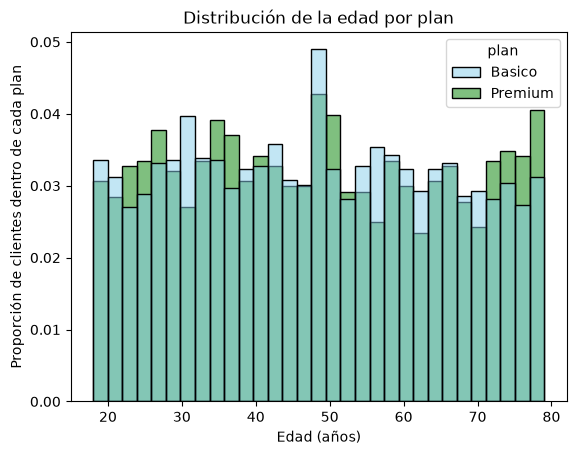

In [32]:
# Histograma para visualizar la edad (age)
# stat='probability' + common_norm=False: cada plan se mide contra su propio total,
# así comparamos formas aunque Básico tenga casi el doble de clientes que Premium
sns.histplot(data=user_profile, x='age', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], bins=31, stat='probability', common_norm=False)
plt.title('Distribución de la edad por plan')
plt.xlabel('Edad (años)')
plt.ylabel('Proporción de clientes dentro de cada plan')
plt.show()

💡Insights:
- Distribución **aproximadamente uniforme** (plana) entre 18 y 79 años, sin sesgo: media (48.1) ≈ mediana (48).
- Básico y Premium tienen la misma forma: **no existe un patrón** de edad por plan.
- El pico en 48 años no es real: son los 55 clientes con -999 que imputamos con la mediana.

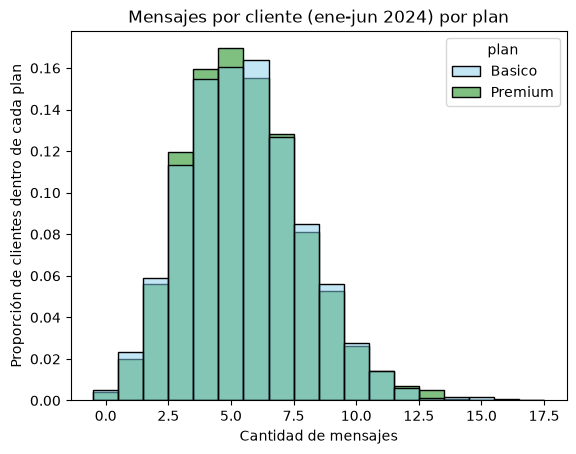

In [33]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], discrete=True, stat='probability', common_norm=False)
plt.title('Mensajes por cliente (ene-jun 2024) por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Proporción de clientes dentro de cada plan')
plt.show()

💡Insights:
- Distribución **ligeramente sesgada a la derecha**: la mayoría envía entre 3 y 7 mensajes en el semestre (mediana 5) y unos pocos llegan hasta 17.
- Las barras de Básico y Premium casi se enciman (media de 5.5 en ambos): **el plan no cambia cuántos mensajes se envían**.

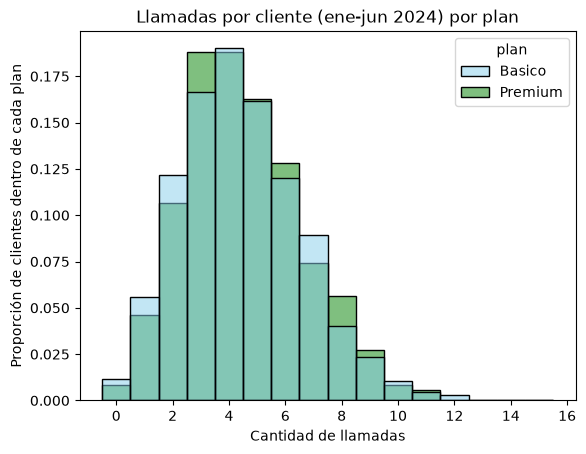

In [34]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], discrete=True, stat='probability', common_norm=False)
plt.title('Llamadas por cliente (ene-jun 2024) por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Proporción de clientes dentro de cada plan')
plt.show()

💡Insights:
- Distribución **ligeramente sesgada a la derecha**: la mayoría hace entre 2 y 6 llamadas en el semestre (mediana 4); el máximo es 15.
- Básico (4.45) y Premium (4.52) se comportan igual: **no existe un patrón por plan**.

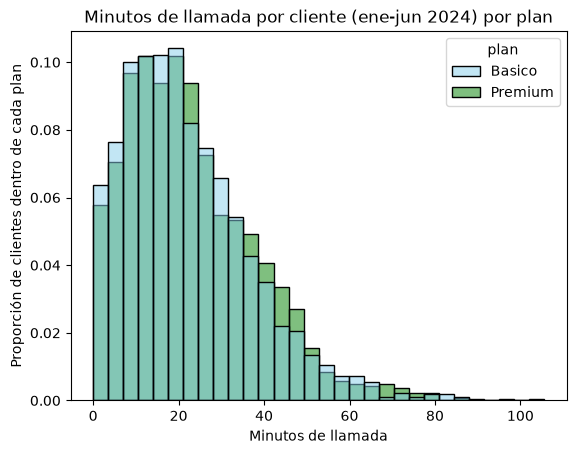

In [35]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], bins=30, stat='probability', common_norm=False)
plt.title('Minutos de llamada por cliente (ene-jun 2024) por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Proporción de clientes dentro de cada plan')
plt.show()

💡Insights:
- Distribución **sesgada a la derecha**: la media (22.4 min) es mayor que la mediana (19.7 min). 3 de cada 4 clientes hablan menos de 31 minutos en el semestre y pocos superan los 60.
- Premium (22.9 min) y Básico (22.2 min) casi no se distinguen: **los clientes Premium no hablan más**, aunque su plan incluye 6 veces más minutos.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

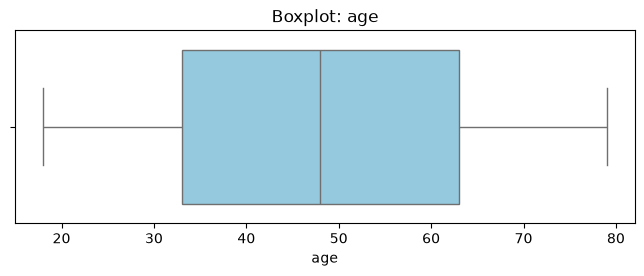

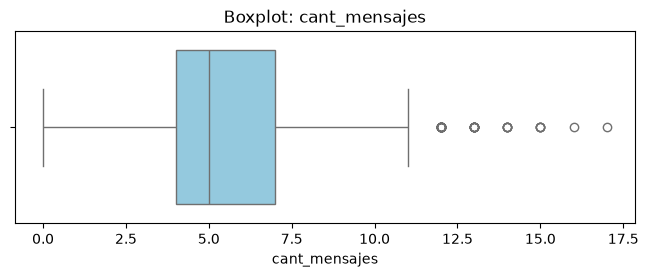

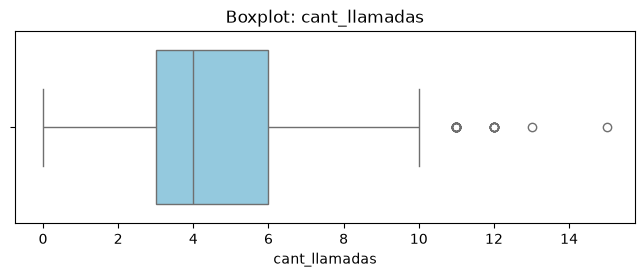

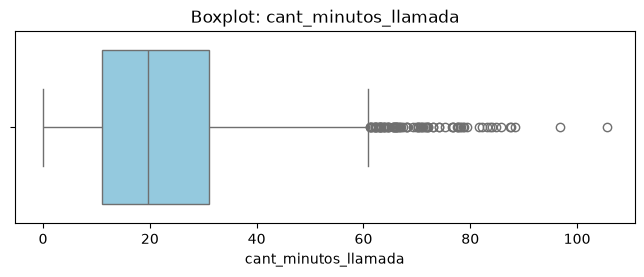

In [36]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- Age: **no presenta outliers**; todos los valores quedan dentro de los bigotes (18 a 79 años).
- cant_mensajes: **sí presenta outliers**, solo del lado alto (clientes con 12 mensajes o más).
- cant_llamadas: **sí presenta outliers**, solo del lado alto (11 llamadas o más).
- cant_minutos_llamada: **sí presenta outliers**, solo del lado alto (más de ~61 minutos); es la variable con más casos.

In [37]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Los outliers solo aparecen del lado alto, así que basta con el límite superior
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    cant_outliers = (user_profile[col] > limite_superior).sum()
    print(f'{col}: Q1 = {Q1:.2f} | Q3 = {Q3:.2f} | IQR = {IQR:.2f} | '
          f'límite superior = {limite_superior:.2f} | outliers = {cant_outliers} '
          f'({cant_outliers / len(user_profile):.1%})')

cant_mensajes: Q1 = 4.00 | Q3 = 7.00 | IQR = 3.00 | límite superior = 11.50 | outliers = 46 (1.1%)
cant_llamadas: Q1 = 3.00 | Q3 = 6.00 | IQR = 3.00 | límite superior = 10.50 | outliers = 30 (0.8%)
cant_minutos_llamada: Q1 = 11.08 | Q3 = 30.99 | IQR = 19.91 | límite superior = 60.86 | outliers = 84 (2.1%)


In [38]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.411225
std,2.359738,2.145139,15.053351
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.080000
50%,5.000000,4.000000,19.670000
75%,7.000000,6.000000,30.992500
max,17.000000,15.000000,105.540000


💡Insights:
- cant_mensajes: **mantener**. Hay 46 clientes (1.1%) arriba del límite de 11.5 mensajes; el máximo (17) es perfectamente posible para una persona. Son clientes reales que usan más el servicio, no errores.
- cant_llamadas: **mantener**. Hay 30 clientes (0.8%) arriba del límite de 10.5 llamadas; el máximo (15) también es posible.
- cant_minutos_llamada: **mantener**. Hay 84 clientes (2.1%) arriba del límite de 60.86 minutos; el máximo (105.5 minutos en 6 meses, ≈ 18 minutos al mes) es real y moderado. Los únicos valores imposibles (llamadas de 120 minutos exactos) ya los tratamos como sentinels en el paso 3.1.

No conviene eliminarlos ni caparlos: son los clientes más activos, justo los que queremos estudiar en la segmentación. Tampoco hay señales de fraude: un fraude se vería como cientos de llamadas o de minutos, no 15 llamadas en medio año.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [39]:
# Crear columna grupo_uso
def clasificar_uso(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']
    # Manejo de valores faltantes
    if pd.isna(llamadas) or pd.isna(mensajes):
        return 'Error en datos'
    # Reglas, de la más restrictiva a la menos restrictiva
    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)
user_profile['grupo_uso'].value_counts()

grupo_uso
Uso medio    2943
Bajo uso      779
Alto uso      278
Name: count, dtype: int64

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [41]:
# Crear columna grupo_edad
def clasificar_edad(row):
    edad = row['age']
    # Manejo de valores faltantes
    if pd.isna(edad):
        return 'Error en datos'
    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)
user_profile['grupo_edad'].value_counts()

grupo_edad
Adulto          2018
Adulto Mayor    1222
Joven            760
Name: count, dtype: int64

In [42]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

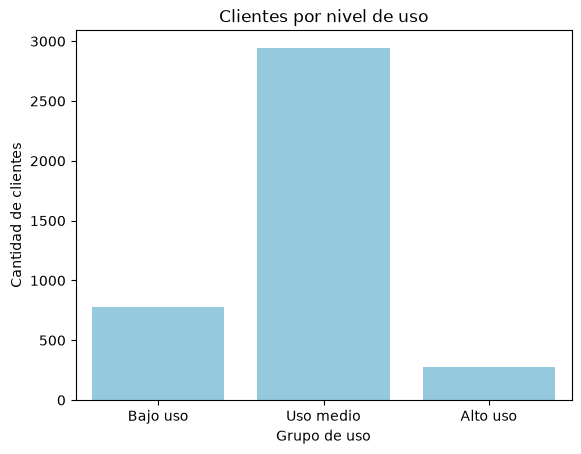

In [43]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Clientes por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')
plt.show()

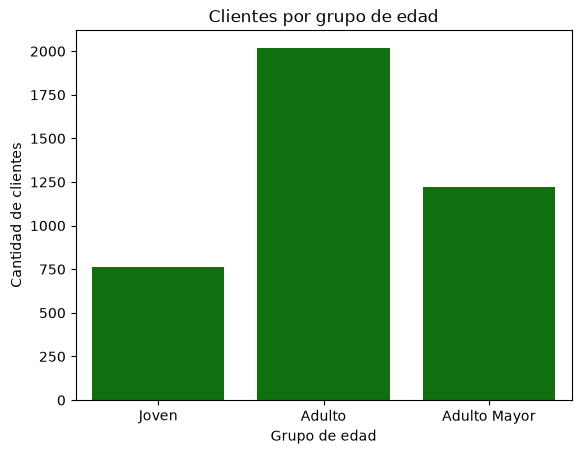

In [44]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='green')
plt.title('Clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')
plt.show()

💡Insights:
- **Por uso:** 3 de cada 4 clientes son de *Uso medio* (2,943, 74%); 779 son de *Bajo uso* (19%) y solo 278 de *Alto uso* (7%).
- **Por edad:** la mitad son *Adultos* de 30 a 59 años (2,018, 50%); les siguen los *Adultos Mayores* (1,222, 31%) y los *Jóvenes* (760, 19%).

### 6.4 Extra: cruces para responder las preguntas del negocio

Los conteos de 6.3 dicen *cuántos* clientes hay en cada grupo, pero no responden *cómo cambia el uso según la edad, el plan o el país*, ni *qué segmento vale más*. Para eso cruzamos las variables.

In [45]:
# Extra: ¿el nivel de uso cambia según la edad? (% de clientes de cada grupo de edad; cada fila suma 100)
uso_por_edad = pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index') * 100
uso_por_edad.round(1).loc[['Joven', 'Adulto', 'Adulto Mayor'], ['Bajo uso', 'Uso medio', 'Alto uso']]

grupo_uso,Bajo uso,Uso medio,Alto uso
grupo_edad,,,
Joven,20.7,72.6,6.7
Adulto,18.1,74.3,7.6
Adulto Mayor,21.0,72.9,6.1


In [46]:
# Extra: promedio de uso por segmento, plan y país
def obtener_pais(ciudad):
    # Manejo de valores faltantes (los 565 clientes sin ciudad)
    if pd.isna(ciudad):
        return 'Sin dato'
    elif ciudad in ['CDMX', 'GDL', 'MTY']:
        return 'México'
    else:  # Bogotá, Medellín y Cali
        return 'Colombia'

user_profile['pais'] = user_profile['city'].apply(obtener_pais)

for col in ['grupo_uso', 'grupo_edad', 'plan', 'pais']:
    display(user_profile.groupby(col)[columnas_uso].mean().round(2))

,cant_mensajes,cant_llamadas,cant_minutos_llamada
grupo_uso,,,
Alto uso,9.56,5.95,29.72
Bajo uso,3.13,2.80,14.28
Uso medio,5.78,4.78,23.87


,cant_mensajes,cant_llamadas,cant_minutos_llamada
grupo_edad,,,
Adulto,5.55,4.48,22.57
Adulto Mayor,5.49,4.50,22.10
Joven,5.52,4.43,22.49


,cant_mensajes,cant_llamadas,cant_minutos_llamada
plan,,,
Basico,5.53,4.45,22.16
Premium,5.52,4.52,22.88


,cant_mensajes,cant_llamadas,cant_minutos_llamada
pais,,,
Colombia,5.54,4.50,22.65
México,5.48,4.45,22.28
Sin dato,5.59,4.48,22.00


In [47]:
# Extra: ¿cuánto de su plan usan los clientes? (usage cubre 6 meses: enero a junio de 2024)
meses = 6
consumo = user_profile.merge(plans, left_on='plan', right_on='plan_name', how='left')
consumo['minutos_por_mes'] = consumo['cant_minutos_llamada'] / meses
consumo['mensajes_por_mes'] = consumo['cant_mensajes'] / meses
consumo['pct_minutos_usados'] = consumo['minutos_por_mes'] / consumo['minutes_included'] * 100
consumo['pct_mensajes_usados'] = consumo['mensajes_por_mes'] / consumo['messages_included'] * 100

display(consumo.groupby('plan')[['minutos_por_mes', 'mensajes_por_mes', 'pct_minutos_usados', 'pct_mensajes_usados']].mean().round(2))
print('Clientes que rebasan sus minutos incluidos:', (consumo['pct_minutos_usados'] > 100).sum())
print('Clientes que rebasan sus mensajes incluidos:', (consumo['pct_mensajes_usados'] > 100).sum())
print('Máximo % de minutos usados por un cliente:', consumo['pct_minutos_usados'].max().round(1))

# Ingreso mensual por suscripción de los clientes activos (no hay cargos extra: nadie rebasa su plan)
activos = consumo[consumo['churn_date'].isna()]
ingreso = activos.groupby('plan').agg(clientes=('user_id', 'count'), ingreso_usd=('usd_monthly_pay', 'sum'))
ingreso['pct_ingreso'] = (ingreso['ingreso_usd'] / ingreso['ingreso_usd'].sum() * 100).round(1)
ingreso

,minutos_por_mes,mensajes_por_mes,pct_minutos_usados,pct_mensajes_usados
plan,,,,
Basico,3.69,0.92,3.69,0.92
Premium,3.81,0.92,0.64,0.18


Clientes que rebasan sus minutos incluidos: 0
Clientes que rebasan sus mensajes incluidos: 0
Máximo % de minutos usados por un cliente: 17.6


,clientes,ingreso_usd,pct_ingreso
plan,,,
Basico,2297,27564,47.1
Premium,1237,30925,52.9


In [48]:
# Extra: cancelaciones (churn): churn_date con dato = el cliente canceló; vacío = sigue activo
print('Así viene churn_date (formato dañado, notación científica):', user_profile['churn_date'].dropna().head(3).tolist())
user_profile['cancelo'] = user_profile['churn_date'].notna()
print('Tasa de cancelación global:', round(user_profile['cancelo'].mean() * 100, 1), '%')

for col in ['plan', 'pais', 'grupo_edad', 'grupo_uso']:
    display((user_profile.groupby(col)['cancelo'].mean() * 100).round(1))

Así viene churn_date (formato dañado, notación científica): ['1,71832E+18', '1,7261E+18', '1,72169E+18']
Tasa de cancelación global: 11.6 %


plan
Basico     11.5
Premium    12.0
Name: cancelo, dtype: float64

pais
Colombia    11.8
México      11.9
Sin dato    10.4
Name: cancelo, dtype: float64

grupo_edad
Adulto          12.5
Adulto Mayor    11.0
Joven           10.5
Name: cancelo, dtype: float64

grupo_uso
Alto uso     14.0
Bajo uso     11.4
Uso medio    11.5
Name: cancelo, dtype: float64

💡Insights:
- **La edad no cambia el nivel de uso:** el *Alto uso* va de 6.1% (Adultos Mayores) a 7.6% (Adultos), y los tres grupos de edad tienen casi la misma mezcla.
- **El plan y el país tampoco:** Básico y Premium, y México y Colombia, promedian lo mismo (~5.5 mensajes, ~4.5 llamadas y ~22 minutos). Lo único que separa a los clientes es su propio nivel de uso.
- **Los planes están sobrados:** el cliente promedio usa ~3.7 minutos y ~1 mensaje al mes. En Básico eso es el 3.7% de sus minutos incluidos; en Premium, apenas el 0.6%. Nadie rebasa su límite, así que nadie paga cargos extra.
- **Premium es el segmento más valioso en ingreso:** es el 35% de los clientes activos, pero aporta el 52.9% del ingreso mensual por suscripción, con el mismo consumo que Básico.
- **La cancelación es pareja (~12%)** entre planes, países y edades. El *Alto uso* cancela un poco más (14.0%), pero con 278 clientes esa diferencia puede ser azar: hay que vigilarla, no concluir todavía.


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- `age`: 55 registros (1.4%) con el sentinel **-999** → se reemplazaron por la mediana de las edades válidas (48 años).
- `city`: 469 nulos (11.7%) + 96 registros con **"?"** (2.4%) → 565 clientes sin ciudad (14.1%), que se dejaron como nulos.
- `reg_date`: 40 registros (1%) con fecha en **2026**, todos el mismo día y con uso en 2024 → se marcaron como nulos. Además, ~1 de cada 3 usuarios aparece usando el servicio antes de registrarse: la fecha de registro no es confiable.
- `usage`: 30 duraciones de **120 minutos** y 30 longitudes de **1,490 caracteres**, repetidas exactamente y hasta en el tipo de evento equivocado (sentinels) → se convirtieron a nulos. Los 50 eventos sin fecha (0.1%) se conservaron.
- `duration` (55.2%) y `length` (44.7%) tienen nulos **estructurales (MAR)**: las llamadas no tienen longitud y los mensajes no tienen duración → se dejaron como nulos.
- `churn_date`: 88.4% de nulos que **no son datos perdidos**: indican clientes activos. Además, las fechas vienen en un formato dañado (notación científica).


🔍 **Segmentos por Edad**
- Los Adultos (30 a 59 años) son la mitad de la base (50%); les siguen los Adultos Mayores (31%) y los Jóvenes (19%).
- Los tres grupos usan el servicio casi igual: ~5.5 mensajes, ~4.5 llamadas y ~22 minutos por cliente en el semestre. El *Alto uso* va de 6.1% a 7.6% en cada grupo. **La edad no explica el nivel de uso.**


📊 **Segmentos por Nivel de Uso**
- Uso medio: **74%** (2,943) · Bajo uso: **19%** (779) · Alto uso: **7%** (278 clientes).
- El *Alto uso* envía en promedio 9.6 mensajes y habla 30 minutos en el semestre, contra 3.1 mensajes y 14 minutos del *Bajo uso*.
- **Outliers:** 84 clientes con más de 61 minutos, 46 con más de 11 mensajes y 30 con más de 10 llamadas. Son reales y moderados (el máximo equivale a ~18 minutos al mes), sin señales de fraude: se mantuvieron.
- Básico y Premium, y México y Colombia, tienen el mismo comportamiento de uso.


➡️ Esto sugiere que **lo que distingue a los clientes no es quiénes son (edad, país o plan), sino cuánto usan**. Y aun los que más usan consumen poco: el cliente promedio ocupa menos del 4% de los minutos de un plan Básico y menos del 1% de los de un Premium, y nadie rebasa su límite. Premium paga más del doble ($25 contra $12) por el mismo uso de llamadas y mensajes, y aporta el 52.9% del ingreso mensual por suscripción de los clientes activos: es el segmento más valioso, y también el que más motivos tiene para sentir que paga de más.


💡 **Recomendaciones**
- **Proteger a Premium**, el segmento más valioso: si su diferencia está en los datos móviles (GB), comunicarla mejor; si no, ofrecer beneficios o un ajuste de plan antes de que cancelen.
- **Crear un plan de entrada más barato**, con menos minutos y mensajes, para el *Bajo uso* y para atraer clientes sensibles al precio: su consumo real cabe de sobra.
- **Programa de lealtad para el 7% de *Alto uso***: son los clientes más activos y su tasa de cancelación (14.0%) es la más alta, aunque con 278 clientes falta confirmarla.
- **Rediseñar la oferta alrededor de los datos móviles**: los minutos y mensajes incluidos casi no se usan. Antes de cambiar precios hay que validar el consumo de GB, que este análisis no tiene.
- **Mejorar la captura de datos:** corregir el registro de ciudad y de fecha de alta y el formato de `churn_date`, y confirmar que la tabla de uso está completa (~10 eventos por cliente en 6 meses es muy poco).

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`